# Exercise 3
Nico Reiterer - 5191 2112

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

## 3.2

In [2]:
# Data knots given
x = np.array([0, 1, 2, 3, 4], dtype=float)
f = np.array([0, 1, 1, 2, 2], dtype=float)

n = len(x) - 1          # number of intervals
h = np.diff(x)          # interval lengths h_i
N = 4 * n               # number of unknowns


def idx(i, k):
    """Column index of coefficient k (0=a, 1=b, 2=c, 3=d) of piece i."""
    return 4 * i + k


M = np.zeros((N, N))
r = np.zeros(N)
row = 0

# Interpolation at the left end of each piece: a_i = f_i
for i in range(n):
    M[row, idx(i, 0)] = 1
    r[row] = f[i]
    row += 1

# Interpolation at the last knot: s_{n-1}(x_n) = f_n
i = n - 1
M[row, idx(i, 0)] = 1
M[row, idx(i, 1)] = h[i]
M[row, idx(i, 2)] = h[i] ** 2
M[row, idx(i, 3)] = h[i] ** 3
r[row] = f[n]
row += 1

# Smoothness at the interior knots x_1, ..., x_{n-1}
for i in range(n - 1):
    # j=0, no derivative : a_i + b_i h_i + c_i h_i^2 + d_i h_i^3 = a_{i+1}
    M[row, idx(i, 0)] = 1
    M[row, idx(i, 1)] = h[i]
    M[row, idx(i, 2)] = h[i] ** 2
    M[row, idx(i, 3)] = h[i] ** 3
    M[row, idx(i + 1, 0)] = -1
    row += 1

    # j=1: b_i + 2 c_i h_i + 3 d_i h_i^2 = b_{i+1}
    M[row, idx(i, 1)] = 1
    M[row, idx(i, 2)] = 2 * h[i]
    M[row, idx(i, 3)] = 3 * h[i] ** 2
    M[row, idx(i + 1, 1)] = -1
    row += 1

    # j=2: 2 c_i + 6 d_i h_i = 2 c_{i+1}
    M[row, idx(i, 2)] = 2
    M[row, idx(i, 3)] = 6 * h[i]
    M[row, idx(i + 1, 2)] = -2
    row += 1

# Not-a-knot: d_0 = d_1 and d_{n-2} = d_{n-1}
M[row, idx(0, 3)] = 1
M[row, idx(1, 3)] = -1
row += 1
M[row, idx(n - 2, 3)] = 1
M[row, idx(n - 1, 3)] = -1
row += 1

assert row == N, "number of equations must equal number of unknowns"

if __name__ == "__main__":
    np.set_printoptions(linewidth=200)
    print("M =\n", M.astype(int))
    print("r =", r)

    z = np.linalg.solve(M, r)
    coeffs = z.reshape(n, 4)   # row i = (a_i, b_i, c_i, d_i)
    print("\nCoefficients (a_i, b_i, c_i, d_i) per piece:\n", coeffs)

    # Check against scipy (default boundary condition = not-a-knot).
    # cs.c[:, i] stores (d_i, c_i, b_i, a_i), highest power first for some reason 
    # (although I naturally would write the highest power first, only in the 
    # script we start with a0 ... )
    cs = CubicSpline(x, f)
    print("\nMatches scipy CubicSpline:", np.allclose(coeffs, cs.c[::-1].T))

M =
 [[ 1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  1  1  1  1]
 [ 1  1  1  1 -1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  2  3  0 -1  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  2  6  0  0 -2  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  1  1  1 -1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  2  3  0 -1  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  2  6  0  0 -2  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  1  1  1  1 -1  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  1  2  3  0 -1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  2  6  0  0 -2  0]
 [ 0  0  0  1  0  0  0 -1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  1  0  0  0 -1]]
r = [0. 1. 1. 2. 2. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Coefficients (a_i, b_i, c_i, d_i) per piece:
 [[ 0.   2.5 -2.   0.5]
 [ 1.   0.  -0.5  0.5]
 [ 1.   0.5  1.  -0.5]
 [ 2.   

## 3.3

In [3]:
n_list = np.array([10, 20, 40])

# defining the knots
x_unif = lambda n: 5 * (-1 + 2 * np.arange(n + 1) / n)
x_cheb = lambda n: 5 * np.cos((np.arange(n + 1) + 0.5)/(n+1) * np.pi)

# defining the function to interpolate
f = lambda x: (1 + x**2)**(-1)

# defining Neville as in last exercise
def N(f: np.ndarray, x: np.ndarray, x_dash: float) -> np.ndarray:
    """
    Algorithm 1 (Aitken-Neville Scheme) from p.5 of the script

        f: vector f ∈ Rn+
        x: knot vector x ∈ Rn+1
    
    """
    n = len(x)
    N = np.zeros((n, n)) # or rather np.full((n, n), np.nan) because zero could be a value ofc
    N[:,0] = f

    for m in range(1, n):
        for j in range(0, n - m):
            p_jm = (x_dash - x[j]) * N[j + 1, m - 1] - (x_dash - x[j+m]) * N[j, m - 1]
            p_jm /= (x[j+m] - x[j])
            N[j, m] =  p_jm
    
    return N

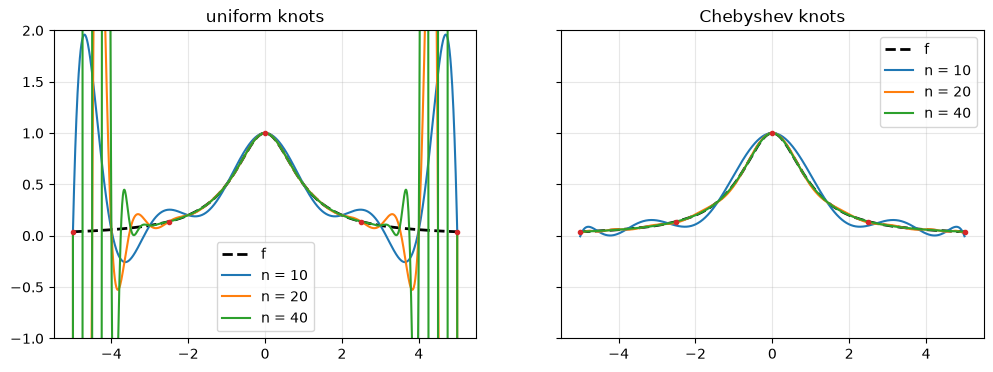

In [ ]:
xe = np.linspace(-5, 5, 1001)

p_cheb = np.array([[N(f(x_cheb(n)), x_cheb(n), t)[0, -1] for t in xe] for n in n_list])
p_unif = np.array([[N(f(x_unif(n)), x_unif(n), t)[0, -1] for t in xe] for n in n_list])
# shapes: (len(n_list), len(xe))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, P, name in zip(axes, [p_unif, p_cheb], ["Uniform", "Chebyshev"]):
    ax.plot(xe, f(xe), "k--", lw=2, label="f")
    ax.plot(xe, P.T, label=[f"n = {n}" for n in n_list])   # all n in one call
    ax.plot(x_unif(n), f(x_unif(n)), ".")
    ax.set_title(f"{name} knots"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylim(-1, 2)   # uniform n=40 blows up near +/-5 as expected, so clipping the view
plt.show()